# 2027 NFL Big Data Bowl — Combine → NFL Success EDA
**Goal:** predict NFL success from combine data. This notebook explores (1) the combine features, (2) how to define the success target, (3) how features relate to the target, (4) the draft-capital confound, and (5) features derived from combine tracking.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
pd.set_option('display.width',200); pd.set_option('display.max_columns',60)
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=90
D='../data/'
pl=pd.read_csv(D+'players.csv'); cr=pd.read_csv(D+'combine_results.csv'); cs=pd.read_csv(D+'player_career_successes.csv')
df=pl.merge(cr.drop(columns='draft_year'),on='nfl_id').merge(cs,on='nfl_id')
print(df.shape); df.head()

(510, 34)


,nfl_id,display_name,draft_year,nfl_position,birth_date,college_name,college_conference,draft_round,draft_pick_within_round,draft_overall_pick,combine_position,combine_height,combine_weight,hand_size,arm_length,wing_span,ten_yd_split,forty,vertical,broad_jump,three_cone,short_shuttle,bench_reps,ngs_athleticism_score,ngs_college_production_score,ngs_final_score,career_offensive_snaps,career_defensive_snaps,career_special_teams_snaps,career_games_active,career_games_started,ap_all_pro_1st_team,ap_all_pro_2nd_team,pro_bowl_original_ballot
0,55867,Will Anderson,2023,DE,2001-09-02,Alabama,Southeastern Conference,1.0,3.0,3.0,DL,75.500,253,9.875,33.875,81.000,1.61,4.60,NaN,NaN,NaN,NaN,NaN,76,99.0,91.0,0,1884,92,51,44,1,0,1
1,55870,Paris Johnson,2023,T,2001-07-31,Ohio State,Big Ten Conference,1.0,6.0,6.0,OL,78.375,313,9.500,36.125,85.125,NaN,NaN,NaN,110.0,NaN,NaN,29.0,81,76.0,80.0,2802,0,169,47,43,0,0,0
2,55874,Darnell Wright,2023,T,2001-08-10,Tennessee,Southeastern Conference,1.0,10.0,10.0,OL,77.375,333,9.000,33.750,82.000,1.81,5.01,29.0,114.0,NaN,NaN,NaN,84,70.0,78.0,3222,0,167,51,49,0,1,0
3,55875,Peter Skoronski,2023,G,2001-07-31,Northwestern,Big Ten Conference,1.0,11.0,11.0,OL,76.000,313,10.000,32.250,79.500,1.75,5.16,34.5,115.0,7.80,NaN,30.0,84,93.0,89.0,3011,0,170,51,48,0,0,0
4,55877,Lukas Van Ness,2023,DE,2001-07-06,Iowa,Big Ten Conference,1.0,13.0,13.0,DL,77.000,272,11.000,34.000,81.750,1.64,4.58,31.0,118.0,7.02,4.32,17.0,77,74.0,80.0,0,1056,387,51,2,0,0,0


## 1. Cohort overview

              n  undrafted
draft_year                
2023        160         44
2024        177         36
2025        173         47


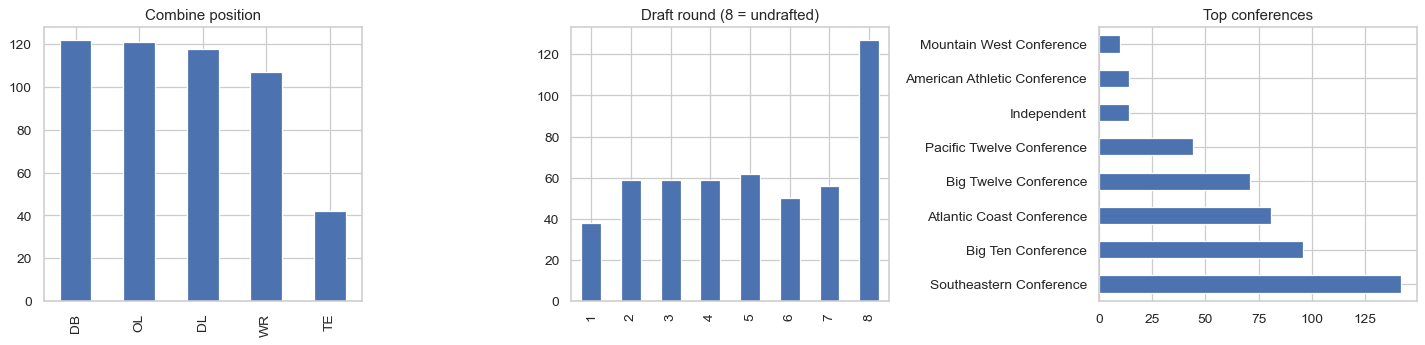

In [2]:
df['undrafted']=df.draft_round.isna()
print(df.groupby('draft_year').agg(n=('nfl_id','size'),undrafted=('undrafted','sum')))
fig,ax=plt.subplots(1,3,figsize=(16,4))
df.combine_position.value_counts().plot.bar(ax=ax[0],title='Combine position')
df.draft_round.fillna(8).astype(int).value_counts().sort_index().plot.bar(ax=ax[1],title='Draft round (8 = undrafted)')
df.college_conference.value_counts().head(8).plot.barh(ax=ax[2],title='Top conferences'); plt.tight_layout()

## 2. Defining the target
Raw career totals are **not comparable across draft classes**: the 2023 class has had up to 3 seasons, 2025 only 1. We normalize by seasons in the league. Games possible ≈ 17 × seasons (2023→3, 2024→2, 2025→1).

In [3]:
df['seasons']=2025-df.draft_year+1
df['games_possible']=17*df.seasons
df['total_snaps']=df.career_offensive_snaps+df.career_defensive_snaps
df['start_rate']=df.career_games_started/df.games_possible
df['active_rate']=df.career_games_active/df.games_possible
df['snaps_per_season']=df.total_snaps/df.seasons
df['honors']=((df.ap_all_pro_1st_team+df.ap_all_pro_2nd_team+df.pro_bowl_original_ballot)>0).astype(int)
print(df.groupby('draft_year')[['career_games_started','career_games_active','total_snaps','start_rate','active_rate','snaps_per_season']].mean().round(2))
print('max games_active by class:',df.groupby('draft_year').career_games_active.max().to_dict())
print('honors:',df.honors.sum(),'players')

            career_games_started  career_games_active  total_snaps  start_rate  active_rate  snaps_per_season
draft_year                                                                                                   
2023                       12.48                33.06       870.12        0.24         0.65            290.04
2024                        8.00                21.94       575.70        0.24         0.65            287.85
2025                        3.43                11.01       262.20        0.20         0.65            262.20
max games_active by class: {2023: 51, 2024: 35, 2025: 17}
honors: 12 players


Zero-start players: 41%
Zero-snap offense+defense players: 21%


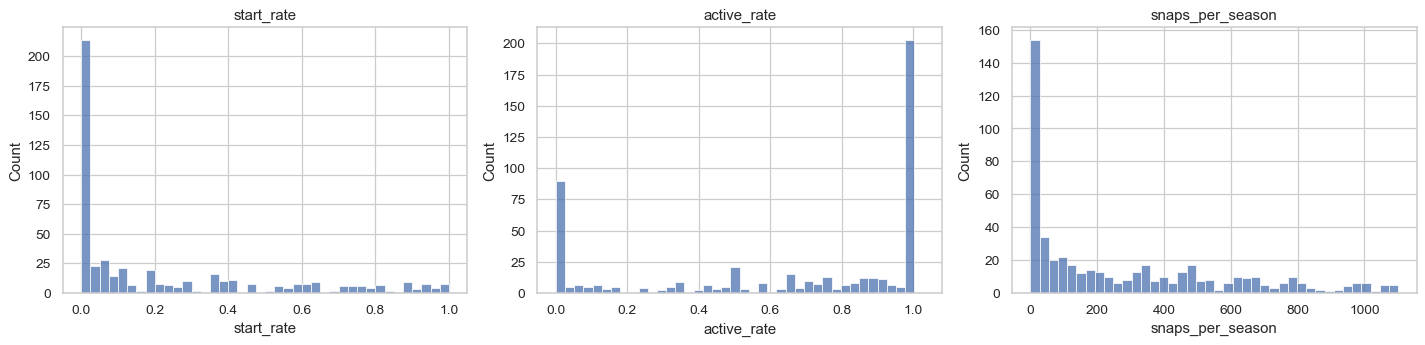

In [4]:
fig,ax=plt.subplots(1,3,figsize=(16,4))
for a,c in zip(ax,['start_rate','active_rate','snaps_per_season']):
    sns.histplot(df[c],bins=40,ax=a); a.set_title(c)
plt.tight_layout()
print('Zero-start players: %.0f%%'%(100*(df.career_games_started==0).mean()))
print('Zero-snap offense+defense players: %.0f%%'%(100*(df.total_snaps==0).mean()))

**Notes on the target.** `start_rate` is heavily zero-inflated and skewed; rare honors (12 players) are too sparse to model directly. Candidate targets: `start_rate` (regression), `snaps_per_season` (regression, position-adjusted), or a binary "became a starter" label. Special-teamers have 0 off/def snaps, so check how many are really contributors.

In [5]:
df['starter']=(df.start_rate>=0.25).astype(int)   # started >=25% of possible games
print(df.starter.mean().round(3)); print(df.groupby('combine_position')[['starter','start_rate','snaps_per_season']].mean().round(2))
print(df.groupby('draft_year').starter.mean().round(3))

0.327
                  starter  start_rate  snaps_per_season
combine_position                                       
DB                   0.31        0.22            278.37
DL                   0.22        0.16            222.69
OL                   0.43        0.33            363.15
TE                   0.36        0.23            247.15
WR                   0.34        0.20            263.15
draft_year
2023    0.350
2024    0.345
2025    0.289
Name: starter, dtype: float64


## 3. Combine feature quality

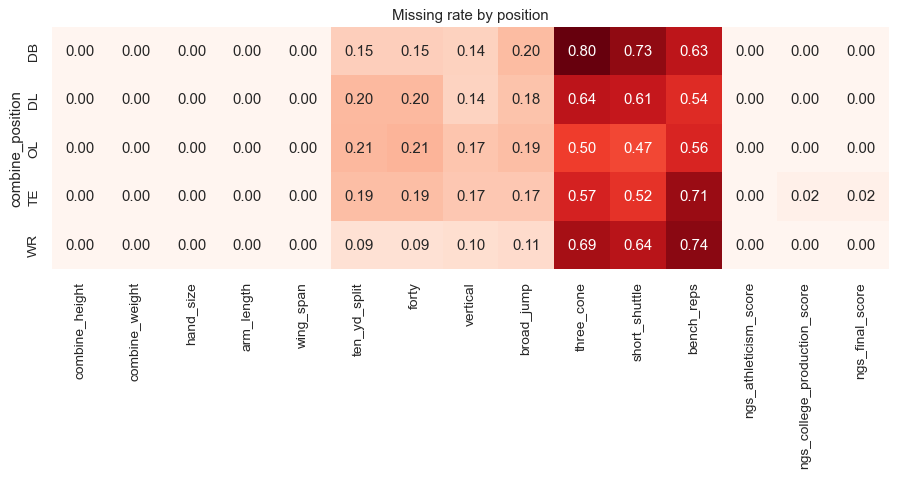

Missing 40 time: drafted 0.15 vs undrafted 0.21


In [6]:
feats=['combine_height','combine_weight','hand_size','arm_length','wing_span','ten_yd_split','forty','vertical','broad_jump','three_cone','short_shuttle','bench_reps','ngs_athleticism_score','ngs_college_production_score','ngs_final_score']
miss=df.groupby('combine_position')[feats].apply(lambda d:d.isna().mean())
plt.figure(figsize=(12,3.5)); sns.heatmap(miss,annot=True,fmt='.2f',cmap='Reds',cbar=False); plt.title('Missing rate by position'); plt.show()
print('Missing 40 time: drafted %.2f vs undrafted %.2f'%(df[~df.undrafted].forty.isna().mean(),df[df.undrafted].forty.isna().mean()))

                              count    mean    std     min     25%     50%     75%     max
combine_height                510.0   74.58   2.63   68.12   72.62   75.00   76.50   80.62
combine_weight                510.0  248.38  53.25  154.00  198.00  245.50  304.00  374.00
hand_size                     510.0    9.57   0.60    8.00    9.12    9.50   10.00   11.62
arm_length                    510.0   32.41   1.42   28.50   31.38   32.38   33.50   36.88
wing_span                     510.0   78.47   3.27   69.00   76.25   78.50   80.84   88.25
ten_yd_split                  425.0    1.63   0.12    1.46    1.54    1.59    1.74    1.96
forty                         424.0    4.73   0.31    4.28    4.47    4.62    5.01    5.48
vertical                      438.0   33.81   4.14   23.00   31.00   34.00   37.00   44.00
broad_jump                    423.0  118.15   9.06   93.00  111.00  120.00  125.00  138.00
three_cone                    180.0    7.31   0.39    6.57    7.00    7.29    7.62    8.19

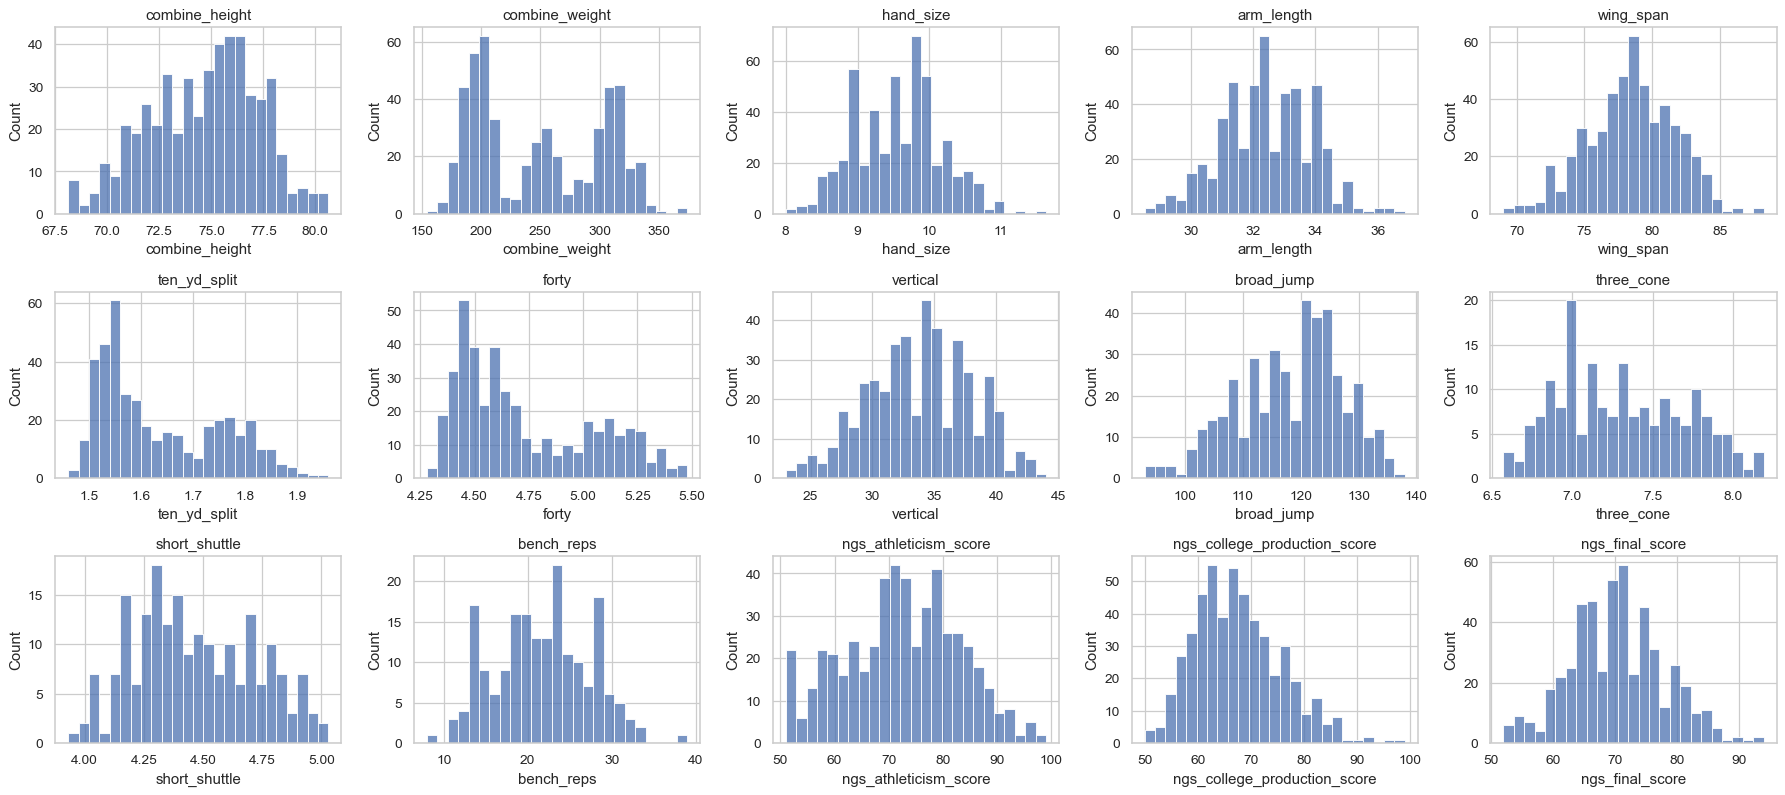

In [7]:
print(df[feats].describe().T.round(2))
fig,axs=plt.subplots(3,5,figsize=(20,9))
for a,c in zip(axs.flat,feats): sns.histplot(df[c].dropna(),bins=25,ax=a); a.set_title(c)
plt.tight_layout()

Measurables differ a lot by position, so the raw values are mostly encoding position. Features need to be **standardized within position group**.

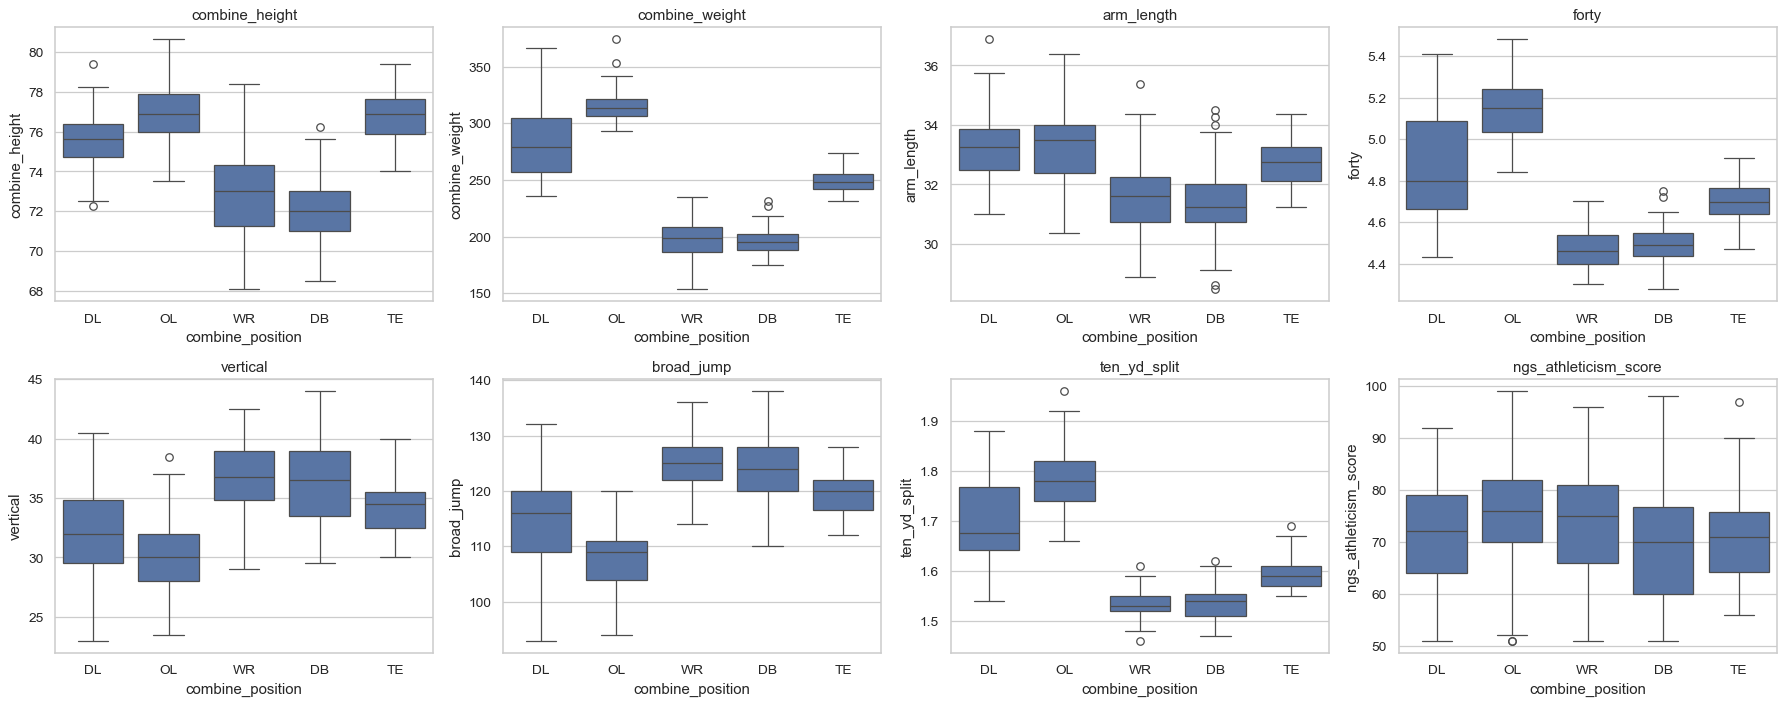

In [8]:
fig,axs=plt.subplots(2,4,figsize=(20,8))
for a,c in zip(axs.flat,['combine_height','combine_weight','arm_length','forty','vertical','broad_jump','ten_yd_split','ngs_athleticism_score']):
    sns.boxplot(data=df,x='combine_position',y=c,ax=a); a.set_title(c)
plt.tight_layout()
# within-position z-scores
for c in feats: df[c+'_z']=df.groupby('combine_position')[c].transform(lambda s:(s-s.mean())/s.std())
# derived
df['bmi']=df.combine_weight/df.combine_height**2*703
df['speed_score']=df.combine_weight*200/df.forty**4
df['burst']=df.vertical+df.broad_jump/ (df.broad_jump.mean()/df.vertical.mean())
df['wingspan_ratio']=df.wing_span/df.combine_height

## 4. Features vs. outcomes

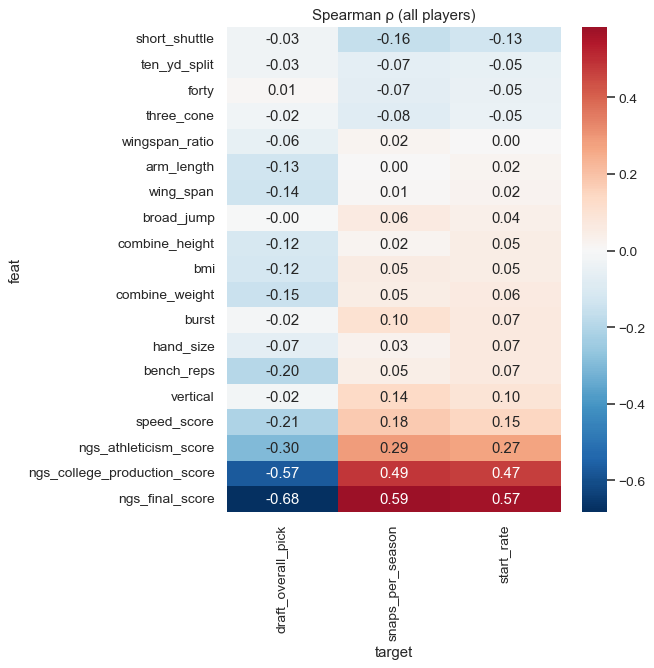

In [9]:
rows=[]
for c in feats+['bmi','speed_score','burst','wingspan_ratio']:
    for t in ['start_rate','snaps_per_season','draft_overall_pick']:
        d=df[[c,t]].dropna()
        r,p=spearmanr(d[c],d[t]); rows.append((c,t,r,len(d)))
r=pd.DataFrame(rows,columns=['feat','target','rho','n']).pivot(index='feat',columns='target',values='rho')
plt.figure(figsize=(6,7)); sns.heatmap(r.sort_values('start_rate'),annot=True,fmt='.2f',cmap='RdBu_r',center=0); plt.title('Spearman ρ (all players)'); plt.show()

The same correlations **within position** (z-scored), which removes position-driven effects:

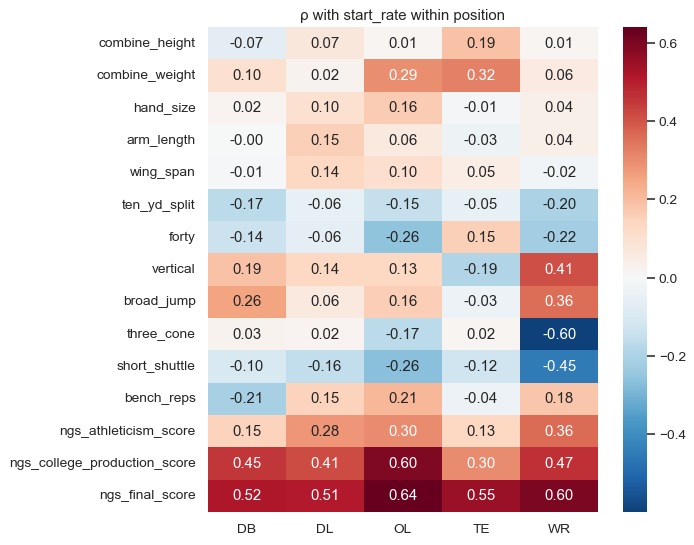

In [10]:
zf=[c for c in df.columns if c.endswith('_z')]
res={}
for pos,g in df.groupby('combine_position'):
    res[pos]=[spearmanr(g[c],g.start_rate,nan_policy='omit')[0] for c in zf]
R=pd.DataFrame(res,index=[c[:-2] for c in zf])
plt.figure(figsize=(7,7)); sns.heatmap(R,annot=True,fmt='.2f',cmap='RdBu_r',center=0); plt.title('ρ with start_rate within position'); plt.show()

## 5. The draft-capital confound
Draft pick is the strongest predictor of playing time (teams play who they paid for), and NGS scores track pick. A model has to decide whether it predicts *success* or *where a player gets drafted*. Below: how much signal remains once pick is controlled.

rho(pick,start_rate)=-0.70


<Axes: title={'center': 'Within-position z: raw vs pick-controlled ρ with start_rate'}>

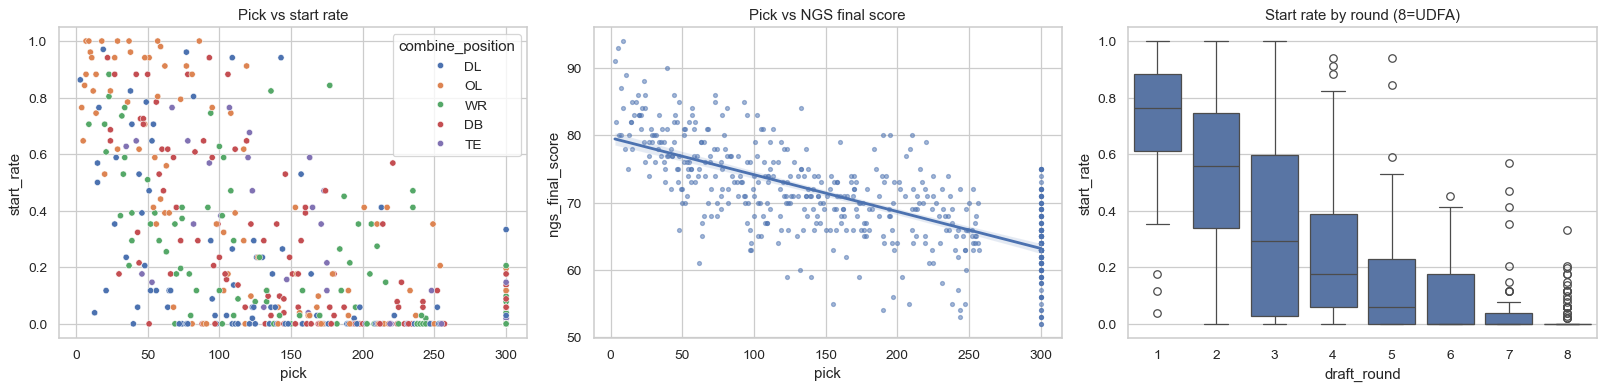

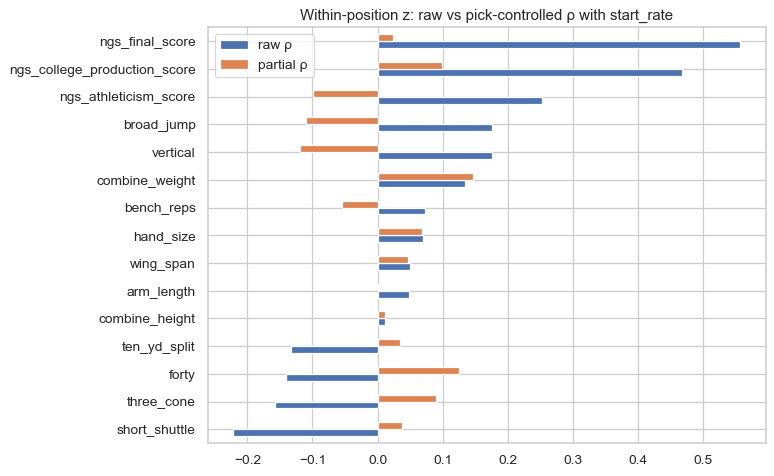

In [11]:
d=df.copy(); d['pick']=d.draft_overall_pick.fillna(300)   # undrafted ~ after pick 257
fig,ax=plt.subplots(1,3,figsize=(18,4.5))
sns.scatterplot(data=d,x='pick',y='start_rate',hue='combine_position',ax=ax[0],s=25); ax[0].set_title('Pick vs start rate')
sns.regplot(data=d,x='pick',y='ngs_final_score',scatter_kws=dict(s=10,alpha=.5),ax=ax[1]); ax[1].set_title('Pick vs NGS final score')
sns.boxplot(data=d,x=d.draft_round.fillna(8).astype(int),y='start_rate',ax=ax[2]); ax[2].set_title('Start rate by round (8=UDFA)')
plt.tight_layout()
print('rho(pick,start_rate)=%.2f'%spearmanr(d.pick,d.start_rate)[0])
# partial correlation: residualize start_rate and feature on log(pick)
from numpy.polynomial import polynomial as P
x=np.log(d.pick)
def resid(y):
    m=y.notna(); b=np.polyfit(x[m],y[m],2); o=pd.Series(np.nan,index=y.index); o[m]=y[m]-np.polyval(b,x[m]); return o
ry=resid(d.start_rate)
part=pd.Series({c:spearmanr(resid(d[c]),ry,nan_policy='omit')[0] for c in zf},name='partial ρ')
raw=pd.Series({c:spearmanr(d[c],d.start_rate,nan_policy='omit')[0] for c in zf},name='raw ρ')
cmp=pd.concat([raw,part],axis=1); cmp.index=[i[:-2] for i in cmp.index]; cmp.round(3).sort_values('raw ρ').plot.barh(figsize=(8,6),title='Within-position z: raw vs pick-controlled ρ with start_rate')

If the partial ρ values collapse toward 0, combine measurables carry little information beyond what draft position already encodes → consider (a) excluding pick from features, or (b) modeling *residual* success over draft expectation.

## 6. Does the NGS score add anything?

In [12]:
import statsmodels.formula.api as smf
d2=d.dropna(subset=['ngs_final_score','start_rate']).copy()
for f in ['start_rate ~ np.log(pick)','start_rate ~ ngs_final_score','start_rate ~ np.log(pick)+ngs_final_score','start_rate ~ np.log(pick)+ngs_athleticism_score+ngs_college_production_score+C(combine_position)']:
    m=smf.ols(f,d2).fit(); print('%-95s R2=%.3f adjR2=%.3f'%(f,m.rsquared,m.rsquared_adj))

start_rate ~ np.log(pick)                                                                       R2=0.508 adjR2=0.507
start_rate ~ ngs_final_score                                                                    R2=0.317 adjR2=0.316
start_rate ~ np.log(pick)+ngs_final_score                                                       R2=0.512 adjR2=0.510
start_rate ~ np.log(pick)+ngs_athleticism_score+ngs_college_production_score+C(combine_position) R2=0.540 adjR2=0.534


## 7. Combine tracking features
`combine_tracking.csv` has 10 Hz tracking for each drill attempt. We can derive richer athletic metrics than the stopwatch time (peak speed, peak acceleration, split profiles). Example: 40-yard dash.

In [13]:
ct=pd.read_csv(D+'combine_tracking.csv',usecols=['draft_year','event_id','nfl_id','entity_type','time','drill_type','attempt','x','y','s','a'])
ct=ct[ct.entity_type=='PLAYER']
print(ct.groupby('drill_type').nfl_id.nunique())
f40=ct[ct.drill_type=='FORTY_YARD_DASH'].copy()
f40['t']=pd.to_datetime(f40.time)
f40=f40.sort_values(['event_id','t'])
f40['sec']=(f40.t-f40.groupby('event_id').t.transform('min')).dt.total_seconds()
att=f40.groupby(['nfl_id','event_id']).agg(top_speed=('s','max'),peak_acc=('a','max'),dur=('sec','max'),n=('s','size')).reset_index()
print(att.describe().T.round(2))

drill_type
FORTY_YARD_DASH     418
SHORT_SHUTTLE       170
SKILL_DRILLS_DB     122
SKILL_DRILLS_DL     114
SKILL_DRILLS_LB       4
SKILL_DRILLS_OL     121
SKILL_DRILLS_TE      42
SKILL_DRILLS_WR     107
THREE_CONE_DRILL    160
Name: nfl_id, dtype: int64
           count      mean     std       min       25%       50%       75%       max
nfl_id     793.0  57299.61  984.89  55867.00  56220.00  57272.00  58305.00  59278.00
top_speed  793.0     10.38    0.77      8.34      9.72     10.59     11.02     11.85
peak_acc   793.0      5.47    0.75      3.17      4.96      5.45      5.90      9.78
dur        793.0      5.13    0.36      4.40      4.90      5.00      5.40      8.90
n          793.0     52.33    3.59     45.00     50.00     51.00     55.00     90.00


40 tracking coverage: 418/510


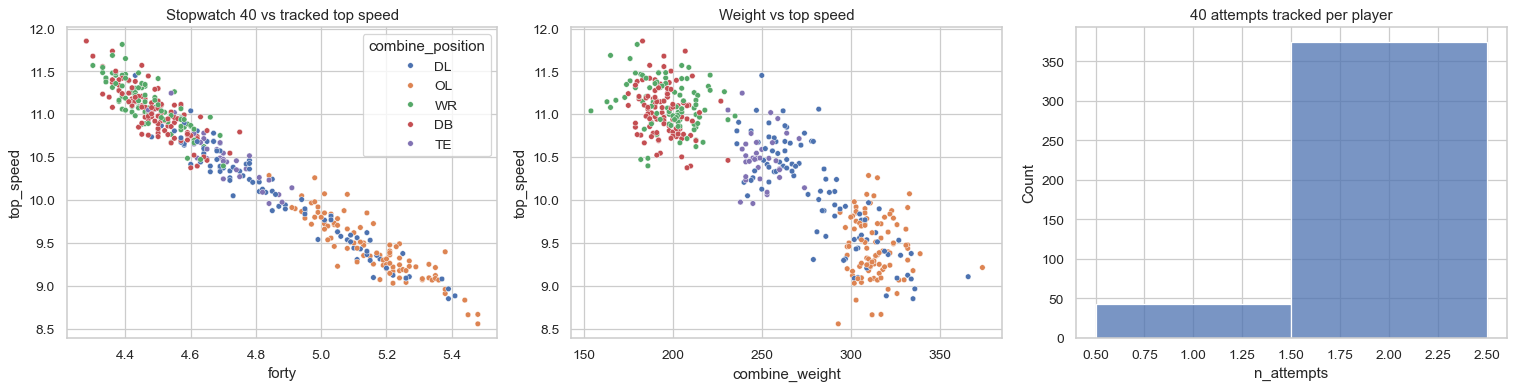

In [14]:
best=att.groupby('nfl_id').agg(top_speed=('top_speed','max'),peak_acc=('peak_acc','max'),n_attempts=('event_id','nunique')).reset_index()
df=df.merge(best,on='nfl_id',how='left')
print('40 tracking coverage: %d/%d'%(df.top_speed.notna().sum(),len(df)))
fig,ax=plt.subplots(1,3,figsize=(17,4.5))
sns.scatterplot(data=df,x='forty',y='top_speed',hue='combine_position',ax=ax[0],s=20); ax[0].set_title('Stopwatch 40 vs tracked top speed')
sns.scatterplot(data=df,x='combine_weight',y='top_speed',hue='combine_position',ax=ax[1],s=20,legend=False); ax[1].set_title('Weight vs top speed')
sns.histplot(df.n_attempts.dropna(),ax=ax[2],discrete=True); ax[2].set_title('40 attempts tracked per player'); plt.tight_layout()

In [15]:
df['top_speed_z']=df.groupby('combine_position').top_speed.transform(lambda s:(s-s.mean())/s.std())
for c in ['top_speed','top_speed_z','peak_acc','forty']:
    print(c, 'ρ with start_rate: %.3f'%spearmanr(df[c],df.start_rate,nan_policy='omit')[0])
print(df.groupby('combine_position')[['top_speed','forty']].corr().iloc[0::2,1].round(2))

top_speed ρ with start_rate: 0.045
top_speed_z ρ with start_rate: 0.131
peak_acc ρ with start_rate: 0.140
forty ρ with start_rate: -0.050
combine_position           
DB                top_speed   -0.80
DL                top_speed   -0.98
OL                top_speed   -0.89
TE                top_speed   -0.91
WR                top_speed   -0.81
Name: forty, dtype: float64


**Tracking quality checks:** after dropping BALL rows, player acceleration is clean (99.9th pct ≈ 8.5 yd/s², max 10.7); the 44 yd/s² outlier seen earlier belongs to the ball. Still filter `entity_type=='PLAYER'` before computing peaks, and note 40-yard attempts have ~50 samples (≈5 s) each. Other drills (3-cone, shuttle, DB/WR route drills, OL/DL drills) can be turned into position-specific features the same way, but each has only 100–200 players.

In [16]:
print(ct.a.describe(percentiles=[.5,.99,.999]).round(2))
print((ct.a>12).mean())

count    431094.00
mean          2.83
std           1.85
min           0.00
50%           2.57
99%           7.40
99.9%         8.54
max          10.72
Name: a, dtype: float64
0.0


## 8. Linking to game performance (alternate targets)

In [17]:
pp=pd.read_csv(D+'player_play.csv',usecols=['nfl_id','game_id','play_id','lined_up_position','expected_points_added','route_ran','pass_result','pressure_allowed','sack_allowed','tackle','target','separation_at_pass_forward'])
g=pd.read_csv(D+'games.csv'); pp=pp.merge(g[['game_id','season_type']],on='game_id'); pp=pp[pp.season_type!='PRE']
s=pp.groupby('nfl_id').agg(plays=('play_id','size'),sep=('separation_at_pass_forward','mean'),pressure=('pressure_allowed','mean'),tackles=('tackle','sum')).reset_index()
x=df.merge(s,on='nfl_id',how='left')
print('players with player_play rows:',x.plays.notna().sum())
print(x[['plays','total_snaps','career_games_started']].corr(method='spearman').round(2))
# WR: separation at pass forward vs combine
w=x[(x.combine_position=='WR')&(x.plays>100)]
print('WR n=%d'%len(w)); print(w[['sep','forty_z','top_speed_z','ngs_final_score_z','draft_overall_pick']].corr(method='spearman').round(2).loc['sep'])
o=x[(x.combine_position=='OL')&(x.plays>200)]
print('OL n=%d'%len(o)); print(o[['pressure','forty_z','combine_weight_z','arm_length_z','draft_overall_pick']].corr(method='spearman').round(2).loc['pressure'])

players with player_play rows: 402
                      plays  total_snaps  career_games_started
plays                  1.00         0.96                  0.89
total_snaps            0.96         1.00                  0.93
career_games_started   0.89         0.93                  1.00
WR n=63
sep                   1.00
forty_z              -0.17
top_speed_z           0.18
ngs_final_score_z    -0.11
draft_overall_pick    0.13
Name: sep, dtype: float64
OL n=67
pressure              1.00
forty_z              -0.10
combine_weight_z      0.07
arm_length_z          0.44
draft_overall_pick    0.06
Name: pressure, dtype: float64


## 9. Takeaways / modeling implications
1. **Target:** use exposure-normalized outcomes (`start_rate`, `snaps_per_season`) — raw totals are confounded by draft year. Zero-inflation and ~510 rows mean simple models (regularized regression, GBM with shallow trees) and careful CV (group by draft year) are the right fit.
2. **Position:** standardize every feature within position group; consider separate models or position interactions.
3. **Missingness:** the agility drills and bench are missing for 60%+ and are informative (non-random). Use indicator flags + imputation, or lean on 40/vertical/broad/10-yd + anthropometrics.
4. **Draft capital:** dominates the signal (log pick alone gives R²≈0.51 for start_rate; adding NGS scores/position only reaches ≈0.54). Decide whether pick is an allowed feature; the pick-controlled view (Section 5) shows what the combine adds beyond it.
5. **Leakage:** `ngs_college_production_score` and `ngs_final_score` encode draft-era scouting information; the NGS athleticism score is derived from the combine metrics themselves.
6. **Tracking-derived features** (peak speed, acceleration profiles, drill-specific splits) are the novel angle; always filter out BALL rows first. Stopwatch 40 and tracked top speed correlate at −0.8 to −0.98 within position, so top speed is mostly redundant with 40 time; acceleration profile/splits are likelier to add new information.
7. **Right-censoring:** the 2025 class has one season of data — its outcomes are noisy; consider validating on 2023/24 and treating 2025 as a holdout.